# 02. Klasifikasi URL MURL — Logistic Regression dengan 54 fitur URL

Notebook ini melatih **Logistic Regression (one-vs-rest)** pada satu representasi URL. Dataset, split domain/IP, audit kebocoran host, dan fungsi transformasi fitur disalin verbatim dari notebook SVM teman, sehingga representasi yang dibandingkan identik. **Hanya metode training yang berbeda.**

Alur: lingkungan → audit data → split domain/IP + audit host → transformasi fitur → metode training → training final → validation → test → penyimpanan hasil → interpretasi.

Tiga file pendukung wajib ada di `DATA_DIR`: `Malicious URL Detection.csv`, `MURL_Split.csv`, `public_suffix_list.dat`.

**Sebelum menjalankan di Google Colab:** unggah ketiga file ke Drive, lalu sesuaikan `DATA_DIR` pada sel pertama. Lingkungan memakai `scikit-learn==1.9.1`, `tldextract==5.3.0`, dan `idna` agar sebanding dengan notebook SVM.

## 1. Persiapan lingkungan

Jalankan sel dari atas. Parameter model baru ditetapkan pada bagian metode, setelah preprocessing selesai.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pathlib import Path
import sys
import importlib.metadata
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()


DATA_DIR = Path("/content/drive/MyDrive/dataset ml ")

print("Interpreter aktif:", sys.executable)
print("Folder kerja    :", ROOT)
print("Folder data     :", DATA_DIR, "| ada:", DATA_DIR.is_dir())
versi = {nama: importlib.metadata.version(nama) for nama in
         ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "ipykernel", "tldextract", "idna"]}
display(pd.Series(versi, name="Versi terpasang").to_frame())


Interpreter aktif: /usr/bin/python3
Folder kerja    : /content
Folder data     : /content/drive/MyDrive/dataset ml  | ada: True


,Versi terpasang
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.9.1
matplotlib,3.10.0
ipykernel,6.17.1
tldextract,5.3.0
idna,3.20


## 2. Memeriksa file pendukung

In [3]:
for nama_file in ["Malicious URL Detection.csv", "MURL_Split.csv", "public_suffix_list.dat"]:
    jalur = DATA_DIR / nama_file
    print(f"{nama_file:32s} ada={jalur.is_file()}  ukuran={jalur.stat().st_size if jalur.is_file() else 0:,}")
assert (DATA_DIR / "Malicious URL Detection.csv").is_file(), "Dataset tidak ditemukan di DATA_DIR."
assert (DATA_DIR / "MURL_Split.csv").is_file(), "MURL_Split.csv tidak ditemukan di DATA_DIR."
assert (DATA_DIR / "public_suffix_list.dat").is_file(), "public_suffix_list.dat tidak ditemukan di DATA_DIR."


Malicious URL Detection.csv      ada=True  ukuran=51,681,357
MURL_Split.csv                   ada=True  ukuran=10,547,309
public_suffix_list.dat           ada=True  ukuran=338,012


## 3. Memuat, membersihkan, dan mengaudit data

Sel ini disalin verbatim dari notebook SVM; hanya nama folder data yang berbeda.

Seluruh 783,705 baris dimuat; tidak ada penghapusan atau pengambilan sampel.
URL dengan spasi ujung yang dibersihkan: 354
Salinan URL berulang yang tetap dipertahankan: 3


,Jumlah,Persentase
label,,
benign,426432,54.412
defacement,95263,12.155
exploit,243,0.031
legitimate,5809,0.741
malware,23592,3.010
phishing,229613,29.298
spam,2753,0.351


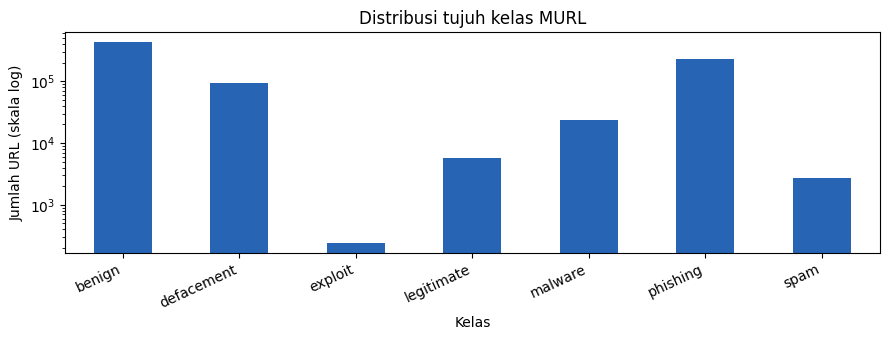

In [4]:
DATA_FILE = DATA_DIR / "Malicious URL Detection.csv"
raw = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
assert raw.columns.tolist() == ["url", "type"] and len(raw) == 783705
df = pd.DataFrame({"row_id": np.arange(len(raw)), "url": raw.url.str.strip(),
                   "label": raw.type.str.strip().str.lower()})
assert df.url.ne("").all() and df.label.ne("").all()
assert sorted(df.label.unique()) == ["benign", "defacement", "exploit", "legitimate", "malware", "phishing", "spam"]
assert df.groupby("url")["label"].nunique().max() == 1, "Ada label bertentangan untuk URL yang sama."
print(f"Seluruh {len(df):,} baris dimuat; tidak ada penghapusan atau pengambilan sampel.")
print("URL dengan spasi ujung yang dibersihkan:", int((raw.url != df.url).sum()))
print("Salinan URL berulang yang tetap dipertahankan:", int(df.url.duplicated().sum()))
counts = df.label.value_counts().sort_index()
display(pd.DataFrame({"Jumlah": counts, "Persentase": counts / len(df) * 100}).round(3))
fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot.bar(ax=ax, logy=True, color="#2864b4")
ax.set(title="Distribusi tujuh kelas MURL", xlabel="Kelas", ylabel="Jumlah URL (skala log)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### Pembagian data dan pemeriksaan kebocoran host

Split domain/IP `icann-domain-disjoint-v3` dibaca dari `MURL_Split.csv`; aturan public suffix dibaca dari `public_suffix_list.dat`. Sel ini disalin verbatim dari notebook SVM; hanya dua baris path yang berbeda.

In [5]:
import ipaddress
import re
import socket
from urllib.parse import urlsplit, unquote
import idna
import tldextract
VERSION = 'icann-domain-disjoint-v3'
ROLES = ('train', 'validation', 'test')
RATIOS = np.array([0.7, 0.15, 0.15])
MAX_OUTER_CLASS_ERROR = 0.005
MAX_TOTAL_ERROR = 0.001
SCHEME = re.compile('^(?:[A-Za-z][A-Za-z0-9+.-]*://|(?:mailto|data|javascript|tel|urn):)', re.I)
SPECIAL_SCHEME = re.compile('^(https?|ftp|ws|wss):[ \\t\\r\\n]*/*', re.I)
C0_SPACE = ''.join((chr(code) for code in range(33)))
NUMERIC_IP = re.compile('^(?:0x[0-9a-f]+|[0-9]+)(?:\\.(?:0x[0-9a-f]+|[0-9]+)){0,3}$', re.I)

def raw_hostname(value):
    value = value.replace('\\', '/').replace('\t', '').replace('\r', '').replace('\n', '').strip(C0_SPACE)
    match = SPECIAL_SCHEME.match(value)
    if match:
        value = match.group(1).lower() + '://' + value[match.end():]
    try:
        parsed = urlsplit(value if SCHEME.match(value) or value.startswith('//') else '//' + value)
        return (parsed.hostname or '').lower().rstrip('.')
    except ValueError:
        return ''

def host_site(host, extract):
    """ICANN eTLD+1 groups all subdomains/tenants; IP aliases use one literal key."""
    host = unquote(host).strip().lower().rstrip('.')
    if not host:
        return ('', 'unresolved-authority')
    try:
        canonical = idna.encode(host, uts46=True).decode('ascii').lower()
    except idna.IDNAError:
        canonical = host
    try:
        address = ipaddress.ip_address(canonical)
        if isinstance(address, ipaddress.IPv6Address) and address.ipv4_mapped is not None:
            address = address.ipv4_mapped
        return (str(address), 'ip:' + str(address))
    except ValueError:
        pass
    if NUMERIC_IP.fullmatch(canonical):
        try:
            address = str(ipaddress.IPv4Address(socket.inet_aton(canonical)))
            return (address, 'ip:' + address)
        except OSError:
            pass
    result = extract(canonical)
    root = result.top_domain_under_public_suffix or '.'.join(canonical.split('.')[-2:])
    try:
        root = idna.encode(root, uts46=True).decode('ascii').lower()
    except idna.IDNAError:
        return (canonical, 'unresolved-authority')
    return (canonical, 'domain:' + root)

def quality_report(urls, labels, hosts, site_ids, indices, classes):
    labels, urls = (np.asarray(labels), np.asarray(urls))
    total = pd.Series(labels).value_counts().reindex(classes).to_numpy()
    counts = np.array([pd.Series(labels[indices[role]]).value_counts().reindex(classes, fill_value=0).to_numpy() for role in ROLES])
    np.testing.assert_array_equal(np.sort(np.concatenate(list(indices.values()))), np.arange(len(urls)))
    assert (counts >= 30).all(), 'Setiap kelas harus terwakili dalam setiap partisi.'
    class_error = float(abs(counts / total - RATIOS[:, None]).max())
    total_error = float(abs(counts.sum(axis=1) / len(urls) - RATIOS).max())
    assert class_error <= MAX_OUTER_CLASS_ERROR and total_error <= MAX_TOTAL_ERROR
    overlap = {}
    for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        a, b = (indices[first], indices[second])
        item = {'site_groups': len(set(site_ids[a]) & set(site_ids[b])), 'hostnames': len(set(hosts[a]) - {''} & set(hosts[b]) - {''}), 'stripped_urls': len(set(urls[a]) & set(urls[b]))}
        assert not any(item.values()), (first, second, item)
        overlap[first + '_vs_' + second] = item
    domain_counts = np.array([[len(np.unique(site_ids[indices[role]][labels[indices[role]] == label])) for label in classes] for role in ROLES])
    assert (domain_counts >= 10).all()
    return {'version': VERSION, 'rows': len(urls), 'site_groups': int(len(np.unique(site_ids))), 'targets': dict(zip(ROLES, RATIOS.tolist())), 'outer_rows': {role: len(indices[role]) for role in ROLES}, 'class_counts': {label: {role: int(counts[i, j]) for i, role in enumerate(ROLES)} for j, label in enumerate(classes)}, 'class_site_counts': {label: {role: int(domain_counts[i, j]) for i, role in enumerate(ROLES)} for j, label in enumerate(classes)}, 'max_outer_class_allocation_error': class_error, 'max_outer_total_error': total_error, 'overlap': overlap}

def load_partitions(df):
    split_file = DATA_DIR / 'MURL_Split.csv'
    psl_file = DATA_DIR / 'public_suffix_list.dat'
    if not split_file.is_file() or not psl_file.is_file():
        raise FileNotFoundError('Letakkan MURL_Split.csv dan public_suffix_list.dat bersama notebook dan CSV dataset.')
    assignment = pd.read_csv(split_file, dtype={'row_id': np.int64, 'split': str}, keep_default_na=False)
    assert assignment.columns.tolist() == ['row_id', 'split']
    assert len(assignment) == len(df) == 783705
    np.testing.assert_array_equal(assignment['row_id'], np.arange(len(df)))
    assert set(assignment['split']) == set(ROLES)
    indices = {role: assignment.loc[assignment['split'] == role, 'row_id'].to_numpy() for role in ROLES}
    extract = tldextract.TLDExtract(suffix_list_urls=[psl_file.resolve().as_uri()], cache_dir=None, fallback_to_snapshot=False, include_psl_private_domains=False)
    raw_hosts = df.url.map(raw_hostname)
    lookup = {host: host_site(host, extract) for host in raw_hosts.unique()}
    hosts = raw_hosts.map(lambda host: lookup[host][0]).to_numpy()
    keys = raw_hosts.map(lambda host: lookup[host][1]).to_numpy()
    site_keys, site_ids = np.unique(keys, return_inverse=True)
    site_ids = site_ids.astype(np.int32)
    classes = sorted(df.label.unique())
    quality = quality_report(df.url.to_numpy(), df.label.to_numpy(), hosts, site_ids, indices, classes)
    quality['unresolved_rows'] = int(np.sum(keys == 'unresolved-authority'))
    return {'indices': indices, 'site_id': site_ids, 'site_keys': site_keys.tolist(), 'hosts': hosts, 'quality': quality, 'version': VERSION}


**Sel penerapan split:** memeriksa penugasan tiap baris, representasi semua kelas, dan tidak adanya irisan domain/IP, hostname, maupun URL. Tabel di bawah harus menunjukkan nol overlap.

In [6]:
design = load_partitions(df)
df["site_id"] = design["site_id"]
df["partisi"] = ""
for role, ids in design["indices"].items():
    df.loc[ids, "partisi"] = role
np.testing.assert_array_equal(
    np.sort(np.concatenate(list(design["indices"].values()))), np.arange(len(df)))
split_counts = pd.crosstab(df.label, df.partisi).reindex(columns=["train", "validation", "test"])
assert (split_counts > 0).all().all() and split_counts.to_numpy().sum() == len(df)
display(split_counts.rename(columns={"train": "Latih", "validation": "Validation", "test": "Test"}))
display(pd.DataFrame(design["quality"]["overlap"]).T)


partisi,Latih,Validation,Test
label,,,
benign,298498,63965,63969
defacement,66674,14295,14294
exploit,170,37,36
legitimate,4066,871,872
malware,16517,3541,3534
phishing,160738,34438,34437
spam,1929,412,412


,site_groups,hostnames,stripped_urls
train_vs_validation,0,0,0
train_vs_test,0,0,0
validation_vs_test,0,0,0


### 2.3 Transformasi fitur — 54 fitur numerik URL

#### Feature engineering: 54 fitur numerik URL

URL tidak dikunjungi. Fitur dihitung dari teks dan struktur URL, tanpa DNS, WHOIS, unduhan halaman, maupun label target.

| Kelompok | Contoh informasi |
| --- | --- |
| Panjang komponen | Panjang URL, hostname, path, query, fragment |
| Komposisi karakter | Jumlah/rasio angka dan huruf, rasio huruf besar, karakter unik, entropi, deret angka terpanjang |
| Struktur hostname | Jumlah titik/tanda hubung, panjang label, rasio angka, IP literal, punycode |
| Struktur URL | Segmen path, parameter query, skema HTTPS, userinfo, port, fragment |
| Pola teks | Hitungan 12 tanda baca dan delapan kata seperti `login`, `verify`, `account` |
| Kondisi parsing | Hostname kosong, parsing gagal, port tidak valid, karakter non-ASCII |

Urutan transformasinya sama pada SVM, Random Forest, dan Decision Tree:

1. **Ekstraksi deterministik:** setiap URL menghasilkan 54 angka dengan urutan kolom yang tetap. URL yang sulit diurai tetap dipakai dan diberi indikator kegagalan; tidak ada baris yang dibuang.
2. **StandardScaler:** setiap fitur diubah dengan `z = (x − rata-rata_train) / simpangan_baku_train`. Rata-rata dan skala hanya dipelajari dari bagian latih; fitur dengan varians nol memakai skala satu.
3. **L2 normalization per baris:** `z / ||z||₂` untuk vektor tak nol. Baris nol tetap nol. Transformasi validation/test memakai statistik latih yang sama tanpa `fit` ulang.

Pohon keputusan umumnya tidak memerlukan standardisasi. Tahap ini tetap dipertahankan untuk menguji **preprocessing yang identik**. L2 normalization per baris dapat mengubah batas pemisahan pohon; hasil ini bukan bukti bahwa preprocessing tersebut paling optimal untuk model pohon. Pengelompokan domain/IP untuk mencegah kebocoran memakai parser kanonis terpisah; teks masukan model tidak diganti dengan hasil kanonisasi itu.

Referensi: [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [Normalizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.Normalizer.html).


**Penjelasan sel kode berikut:** factory menyiapkan ekstraktor 54 fitur, StandardScaler, dan L2 normalization dalam urutan bersama. Ekstraktor lalu dicoba pada tiga URL contoh untuk menampilkan nilai setiap fitur, termasuk input yang gagal diurai. Ekstraksi contoh bersifat deterministik; belum ada statistik scaler yang dipelajari dari dataset. Rata-rata/skala baru di-fit pada bagian fitting train penuh saat training final; validation/test hanya ditransformasi.

Objek pada sel ini adalah pratinjau konfigurasi. Saat training final, pipeline membuat objek baru melalui factory yang sama; statistik fitting hanya dipelajari dari train.

**Sel definisi fungsi:** menyediakan transformasi reusable di dalam notebook. Fungsi hanya membuat objek baru yang belum di-fit; statistik dataset belum dipelajari.


In [7]:
from collections import Counter
from urllib.parse import urlsplit
import ipaddress
import re
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, Normalizer

URL_SCHEME_PREFIX = re.compile('^(?:[A-Za-z][A-Za-z0-9+.-]*://|(?:mailto|data|javascript|tel|urn):)', re.IGNORECASE)

def has_explicit_scheme(value):
    return URL_SCHEME_PREFIX.match(value) is not None

def parsed_url(value):
    try:
        candidate = value if has_explicit_scheme(value) or value.startswith('//') else '//' + value
        parsed = urlsplit(candidate)
        _ = parsed.hostname
        return parsed
    except ValueError:
        return None

def hostname(value):
    parsed = parsed_url(value)
    return (parsed.hostname or '').lower().rstrip('.') if parsed is not None else ''

DIGIT_RUN = re.compile('\\d+')

PERCENT_ESCAPE = re.compile('%[0-9a-fA-F]{2}')

WORDS = ('login', 'verify', 'account', 'secure', 'update', 'bank', 'password', 'signin')

PUNCTUATION = {'dot': '.', 'hyphen': '-', 'underscore': '_', 'slash': '/', 'question': '?', 'equals': '=', 'ampersand': '&', 'at': '@', 'percent': '%', 'hash': '#', 'colon': ':', 'semicolon': ';'}

class URLFeatureExtractor(TransformerMixin, BaseEstimator):
    """Deterministic lexical/structural features; no labels or external lookups."""

    def fit(self, X, y=None):
        return self

    @staticmethod
    def one_url(value):
        counts = Counter(value)
        length = max(len(value), 1)
        lower = value.lower()
        parsed = parsed_url(value)
        host = (parsed.hostname or '').lower().rstrip('.') if parsed is not None else ''
        path = parsed.path if parsed is not None else value
        query = parsed.query if parsed is not None else ''
        fragment = parsed.fragment if parsed is not None else ''
        try:
            port_present = int(parsed.port is not None) if parsed is not None else 0
            invalid_port = 0
        except ValueError:
            port_present, invalid_port = (0, 1)
        try:
            ipaddress.ip_address(host)
            host_is_ip = 1
        except ValueError:
            host_is_ip = 0
        digit_count = sum((count for c, count in counts.items() if c.isdigit()))
        letter_count = sum((count for c, count in counts.items() if c.isalpha()))
        upper_count = sum((count for c, count in counts.items() if c.isupper()))
        host_parts = host.split('.') if host else []
        entropy = -sum((count / length * np.log2(count / length) for count in counts.values()))
        features = {'url_length': len(value), 'hostname_length': len(host), 'path_length': len(path), 'query_length': len(query), 'fragment_length': len(fragment), 'digit_count': digit_count, 'letter_count': letter_count, 'digit_ratio': digit_count / length, 'letter_ratio': letter_count / length, 'uppercase_ratio': upper_count / length, 'nonalphanumeric_ratio': (len(value) - digit_count - letter_count) / length, 'unique_char_ratio': len(counts) / length, 'character_entropy': entropy, 'longest_digit_run': max((len(s) for s in DIGIT_RUN.findall(value)), default=0), 'hostname_dot_count': host.count('.'), 'hostname_hyphen_count': host.count('-'), 'hostname_digit_ratio': sum((c.isdigit() for c in host)) / max(len(host), 1), 'longest_host_label': max(map(len, host_parts), default=0), 'last_host_label_length': len(host_parts[-1]) if host_parts else 0, 'path_segment_count': sum((bool(s) for s in path.split('/'))), 'query_parameter_count': sum((bool(s) for s in query.split('&'))), 'percent_escape_count': len(PERCENT_ESCAPE.findall(value)), 'has_explicit_scheme': int(has_explicit_scheme(value)), 'has_https_scheme': int(lower.startswith('https://')), 'has_query': int(bool(query)), 'has_fragment': int(bool(fragment)), 'has_userinfo': int(bool(parsed is not None and '@' in parsed.netloc)), 'has_explicit_port': port_present, 'invalid_port': invalid_port, 'host_is_ip_literal': host_is_ip, 'host_is_punycode': int(any((part.startswith('xn--') for part in host_parts))), 'parse_failed': int(parsed is None), 'hostname_missing': int(not host), 'non_ascii_count': sum((count for c, count in counts.items() if ord(c) > 127))}
        features.update({'count_' + name: value.count(char) for name, char in PUNCTUATION.items()})
        features.update({'keyword_' + word: lower.count(word) for word in WORDS})
        return features

    def transform(self, X):
        if isinstance(X, str):
            raise TypeError('Pass an iterable of URL strings, not one scalar string.')
        rows = [list(self.one_url(str(value)).values()) for value in X]
        output = np.asarray(rows, dtype=np.float64).reshape(-1, len(self.get_feature_names_out()))
        assert np.isfinite(output).all()
        return output

    def get_feature_names_out(self, input_features=None):
        return np.array(list(self.one_url('example.com').keys()), dtype=object)


def make_preprocessing(representation="feature_engineering"):
    if representation != "feature_engineering":
        raise ValueError("Notebook ini memakai feature engineering.")
    return Pipeline([
        ("url_features", URLFeatureExtractor()),
        ("scaler", StandardScaler()),
        ("unit_length", Normalizer(norm="l2")),
    ])


**Sel contoh penggunaan:** buat satu objek preprocessing, tampilkan konfigurasinya, dan amati contoh transformasi. Ini menunjukkan cara kerja fitur tanpa melakukan fitting pada seluruh dataset. model final akan membuat objek baru melalui fungsi yang sama.


In [8]:
REPRESENTATION = "feature_engineering"
preprocessing = make_preprocessing(REPRESENTATION)
print(preprocessing)
contoh_url = pd.Series(["example.com/login?x=123", "https://127.0.0.1:8443/a", "https://[broken"])
ekstraktor = URLFeatureExtractor()
fitur_contoh = ekstraktor.transform(contoh_url)
assert fitur_contoh.shape == (3, 54) and np.isfinite(fitur_contoh).all()
display(pd.DataFrame(fitur_contoh, index=contoh_url, columns=ekstraktor.get_feature_names_out()).T)
print("Contoh ekstraksi deterministik; scaler belum di-fit pada dataset penuh.")


Pipeline(steps=[('url_features', URLFeatureExtractor()),
                ('scaler', StandardScaler()), ('unit_length', Normalizer())])


,example.com/login?x=123,https://127.0.0.1:8443/a,https://[broken
url_length,23.000000,24.000000,15.000000
hostname_length,11.000000,9.000000,0.000000
path_length,6.000000,2.000000,15.000000
query_length,5.000000,0.000000,0.000000
fragment_length,0.000000,0.000000,0.000000
digit_count,3.000000,10.000000,0.000000
letter_count,16.000000,6.000000,11.000000
digit_ratio,0.130435,0.416667,0.000000
letter_ratio,0.695652,0.250000,0.733333
uppercase_ratio,0.000000,0.000000,0.000000


Contoh ekstraksi deterministik; scaler belum di-fit pada dataset penuh.


## 4. Metode training

Logistic Regression dilatih sebagai **one-vs-rest**: tujuh model biner, satu per kelas. `solver='liblinear'` tidak menerima target multiclass pada scikit-learn 1.9, sehingga `OneVsRestClassifier` dipakai agar skema tetap satu-lawan-sisanya. `C=1.0` dan `class_weight='balanced'` disamakan dengan notebook SVM. Peringatan konvergensi menghentikan proses.

Mulai bagian ini, metode boleh berbeda. Data, preprocessing, split, dan evaluasi tetap sama. Parameter ditetapkan sebelum membaca skor validation/test; tidak ada pencarian hyperparameter.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

MODEL_FAMILY = 'logreg'
SEED = 42
LABEL_MODEL = {MODEL_FAMILY: 'Logistic Regression (one-vs-rest)'}
LR_SETTINGS = dict(C=1.0, class_weight='balanced', solver='liblinear',
                   dual=False, tol=1e-4, max_iter=1000, random_state=SEED)


def make_classifier(family):
    if family != MODEL_FAMILY:
        raise ValueError("Pilih metode yang sesuai dengan notebook ini.")
    # liblinear tidak menerima target multiclass, jadi dibungkus one-vs-rest:
    # tujuh model biner LogisticRegression, satu per kelas.
    return OneVsRestClassifier(LogisticRegression(**LR_SETTINGS))


def kernel_settings(family):
    return None

display(pd.Series(LR_SETTINGS, name="Parameter metode").to_frame())
pemetaan_kernel = kernel_settings(MODEL_FAMILY)
if pemetaan_kernel is not None:
    display(pd.Series(pemetaan_kernel, name="Parameter pemetaan kernel").to_frame())


,Parameter metode
C,1.0
class_weight,balanced
solver,liblinear
dual,False
tol,0.0001
max_iter,1000
random_state,42


**Sel fungsi training dan evaluasi bersama:** pembuatan pipeline, fitting train, fitting model final, perhitungan metrik, confusion matrix, penyimpanan prediksi, dan interpretasi. Isinya disalin dari notebook SVM dengan dua penyesuaian kecil untuk `OneVsRestClassifier`.

In [10]:
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
import json
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
# Hasil disimpan di samping dataset agar tetap ada setelah runtime Colab reset.
RESULTS = DATA_DIR / "results_logreg_disjoint"
VERSIONS = versi
LABEL_REP = {'tfidf': 'TF-IDF karakter', 'feature_engineering': '54 fitur numerik URL'}

def make_model(family, representation):
    steps = [('preprocessing', make_preprocessing(representation))]
    mapping = kernel_settings(family)
    if mapping is not None:
        steps.append(('kernel_map', ClassBalancedNystroem(**mapping)))
    steps.append(('classifier', make_classifier(family)))
    return Pipeline(steps)

def fit_model(model, urls, labels):
    with warnings.catch_warnings(), threadpool_limits(limits=4):
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(urls, labels)
    classifier = model.named_steps['classifier']
    if isinstance(classifier, OneVsRestClassifier):
        assert len(classifier.estimators_) == len(classifier.classes_)
        iterations = [int(est.n_iter_[0]) for est in classifier.estimators_]
        assert max(iterations) < LR_SETTINGS['max_iter'], iterations
    if 'kernel_map' in model.named_steps:
        mapper = model.named_steps['kernel_map']
        assert mapper.fit_input_rows_ == len(urls)
        assert len(set(mapper.landmark_indices_)) == mapper.n_components_
    return model

def save_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8')
    temporary.replace(path)

def metrics(truth, prediction, classes):
    return {'accuracy': float(accuracy_score(truth, prediction)), 'balanced_accuracy': float(balanced_accuracy_score(truth, prediction)), 'macro_f1': float(f1_score(truth, prediction, labels=classes, average='macro', zero_division=0)), 'weighted_f1': float(f1_score(truth, prediction, labels=classes, average='weighted', zero_division=0))}

def report_frame(report, classes):
    records = {label: report[label] for label in classes + ['macro avg', 'weighted avg']}
    frame = pd.DataFrame(records).T
    return frame.rename(columns={'precision': 'Precision', 'recall': 'Recall', 'f1-score': 'F1', 'support': 'Support'}, index={'macro avg': 'Macro average', 'weighted avg': 'Weighted average'})

def context(family, representation, df, design):
    return {'model': family, 'representation': representation, 'split_design_version': 'icann-domain-disjoint-v3', 'row_count': len(df), 'classes': sorted(df.label.unique()), 'seed': SEED, 'versions': VERSIONS, 'classifier_settings': make_classifier(family).estimator.get_params(),
            'decomposition': 'one-vs-rest, 7 binary liblinear models', 'kernel_settings': kernel_settings(family), 'preprocessing': repr(make_preprocessing(representation)), 'split_counts': {role: int(len(ids)) for role, ids in design['indices'].items()}}

def fit_final(family, representation, df, design):
    """Fit preprocessing dan model pada seluruh train; validation/test dikecualikan."""
    meta = context(family, representation, df, design)
    save_json(RESULTS / f'{family}_{representation}_metrics.json', {**meta, 'completed': False, 'run_id': uuid4().hex})
    ids = design['indices']['train']
    model = make_model(family, representation)
    print(f'Melatih {LABEL_MODEL[family]} pada seluruh {len(ids):,} baris train...', flush=True)
    started = perf_counter()
    fit_model(model, df.url.iloc[ids], df.label.iloc[ids])
    seconds = perf_counter() - started
    classifier = model.named_steps['classifier']
    assert classifier.classes_.tolist() == meta['classes']
    assert len(classifier.estimators_) == len(meta['classes'])
    iterations = [int(est.n_iter_[0]) for est in classifier.estimators_]
    assert max(iterations) < LR_SETTINGS['max_iter'], iterations
    print('Iterasi solver per kelas:', iterations)
    if representation == 'feature_engineering':
        assert model.named_steps['preprocessing'].named_steps['scaler'].n_samples_seen_ == len(ids)
    print(f"Selesai dalam {seconds:.1f} detik; jumlah fitur: {model.named_steps['classifier'].n_features_in_:,}.")
    return (model, seconds)

def evaluate(model, role, df, design):
    ids = design['indices'][role]
    truth = df.label.iloc[ids]
    classes = sorted(df.label.unique())
    started = perf_counter()
    prediction = model.predict(df.url.iloc[ids])
    seconds = perf_counter() - started
    score = metrics(truth, prediction, classes)
    report = classification_report(truth, prediction, labels=classes, output_dict=True, zero_division=0)
    cm = confusion_matrix(truth, prediction, labels=classes)
    assert cm.sum() == len(ids)
    title = 'Validation' if role == 'validation' else 'Test'
    print(f'{title}: {len(ids):,} baris; prediksi {seconds:.1f} detik.')
    display(pd.DataFrame([score], index=[title]).round(4))
    display(report_frame(report, classes).round(4))
    if role == 'test':
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        for ax, matrix, name, fmt in [(axes[0], cm, 'Jumlah prediksi', 'd'), (axes[1], cm / cm.sum(axis=1, keepdims=True), 'Recall per kelas', '.2f')]:
            ConfusionMatrixDisplay(matrix, display_labels=classes).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45, values_format=fmt)
            ax.set(title=f'Confusion matrix — {name}', xlabel='Predicted class', ylabel='Actual class')
        plt.tight_layout()
        plt.show()
        i = classes.index('exploit')
        print(f'Kelas exploit: {cm[i, i]}/{cm[i].sum()} terdeteksi. Perhatikan jumlah contoh yang kecil.')
    return {'metrics': score, 'report': report, 'confusion_matrix': cm.tolist(), 'predict_seconds': seconds, 'prediction': prediction}

def save_result(family, representation, model, fit_seconds, validation, test, df, design):
    meta = context(family, representation, df, design)
    key = f'{family}_{representation}'
    run_id = uuid4().hex
    files = {}
    for role, result in [('validation', validation), ('test', test)]:
        path = RESULTS / f'{key}_{role}_predictions.csv.gz'
        ids = design['indices'][role]
        pd.DataFrame({'row_id': ids, 'y_true': df.label.iloc[ids].to_numpy(), 'y_pred': result['prediction'], 'run_id': run_id}).to_csv(path, index=False, compression='gzip')
        files[role] = path.name
    summary = {**meta, 'completed': True, 'run_id': run_id, 'fit_seconds': fit_seconds, 'solver_iterations': [int(est.n_iter_[0]) for est in model.named_steps['classifier'].estimators_], 'input_features': int(model.named_steps['classifier'].n_features_in_), 'validation': validation['metrics'], 'test': test['metrics'], 'validation_report': validation['report'], 'test_report': test['report'], 'test_confusion_matrix': test['confusion_matrix'], 'prediction_files': files, 'completed_at_utc': datetime.now(timezone.utc).isoformat()}
    save_json(RESULTS / f'{key}_metrics.json', summary)
    report_frame(test['report'], meta['classes']).to_csv(RESULTS / f'{key}_test_report.csv')
    return summary

def interpretation(summary):
    report, classes = (summary['test_report'], summary['classes'])
    weakest = min(classes, key=lambda label: report[label]['f1-score'])
    print(f"{LABEL_MODEL[summary['model']]} + {LABEL_REP[summary['representation']]}:")
    print(f"Accuracy test {summary['test']['accuracy']:.2%}; macro F1 {summary['test']['macro_f1']:.4f}.")
    print(f"Kelas dengan F1 terendah: {weakest} ({report[weakest]['f1-score']:.4f}).")
    print('Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi. Hasil berlaku pada protokol ini; data tidak memuat timestamp, source, atau campaign.')


## 5. Melatih model final pada seluruh train

Pipeline baru difit pada seluruh 548.592 baris train. Validation dan test tetap dikecualikan.

In [11]:
model, fit_seconds = fit_final(MODEL_FAMILY, REPRESENTATION, df, design)


Melatih Logistic Regression (one-vs-rest) pada seluruh 548,592 baris train...
Iterasi solver per kelas: [9, 8, 13, 10, 8, 8, 9]
Selesai dalam 273.2 detik; jumlah fitur: 54.


## 6. Evaluasi validation

Accuracy, balanced accuracy, macro F1, weighted F1, serta precision/recall/F1 per kelas. Hasil validation hanya untuk diagnosis; konfigurasi tidak diubah.

In [12]:
validation = evaluate(model, "validation", df, design)


Validation: 117,559 baris; prediksi 18.9 detik.


,accuracy,balanced_accuracy,macro_f1,weighted_f1
Validation,0.5286,0.5002,0.3446,0.5854


,Precision,Recall,F1,Support
benign,0.7764,0.5022,0.6099,63965.0
defacement,0.6075,0.7690,0.6788,14295.0
exploit,0.0036,0.0270,0.0064,37.0
legitimate,0.0540,0.8381,0.1014,871.0
malware,0.4387,0.4773,0.4572,3541.0
phishing,0.6057,0.4773,0.5339,34438.0
spam,0.0127,0.4102,0.0247,412.0
Macro average,0.3569,0.5002,0.3446,117559.0
Weighted average,0.6874,0.5286,0.5854,117559.0


## 7. Evaluasi test

Partisi test sama pada seluruh notebook. Confusion matrix menempatkan kelas sebenarnya pada baris dan kelas prediksi pada kolom. Test hanya memuat 36 contoh exploit; interval kepercayaan kelas ini lebar.

Test: 117,554 baris; prediksi 15.4 detik.


,accuracy,balanced_accuracy,macro_f1,weighted_f1
Test,0.5338,0.4735,0.3467,0.5815


,Precision,Recall,F1,Support
benign,0.8216,0.4943,0.6172,63969.0
defacement,0.5740,0.7874,0.6640,14294.0
exploit,0.0000,0.0000,0.0000,36.0
legitimate,0.0635,0.8165,0.1178,872.0
malware,0.4486,0.5934,0.5109,3534.0
phishing,0.5217,0.4939,0.5074,34437.0
spam,0.0050,0.1286,0.0096,412.0
Macro average,0.3478,0.4735,0.3467,117554.0
Weighted average,0.6837,0.5338,0.5815,117554.0


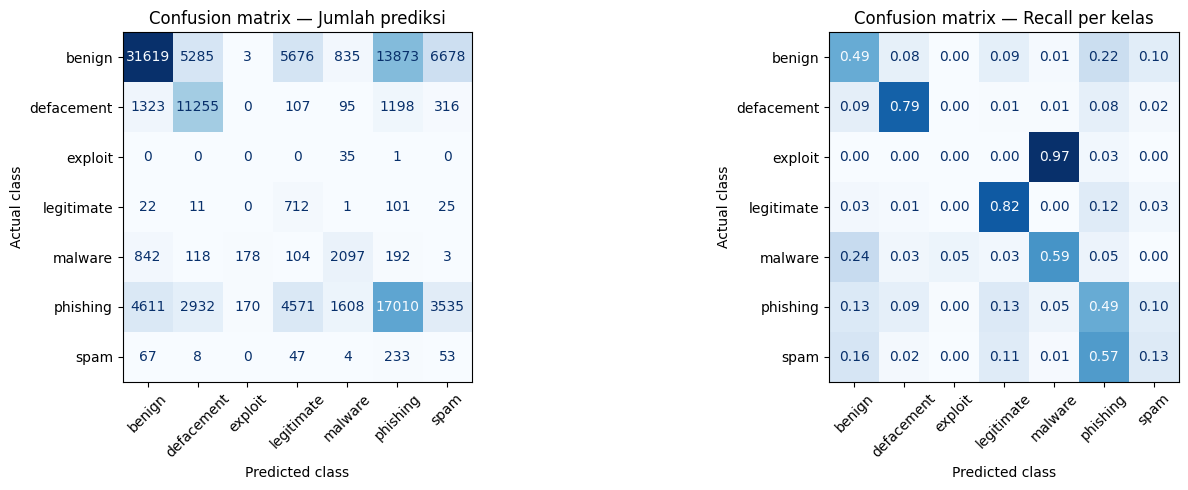

Kelas exploit: 0/36 terdeteksi. Perhatikan jumlah contoh yang kecil.


In [13]:
test = evaluate(model, "test", df, design)


## 8. Menyimpan hasil

Hasil ditulis ke `results_logreg_disjoint/`: prediksi validation/test per baris, laporan per kelas, parameter, versi pustaka, dan identitas baris.

In [14]:
summary = save_result(MODEL_FAMILY, REPRESENTATION, model, fit_seconds,
                      validation, test, df, design)
interpretation(summary)
del model, validation, test
gc.collect()


Logistic Regression (one-vs-rest) + 54 fitur numerik URL:
Accuracy test 53.38%; macro F1 0.3467.
Kelas dengan F1 terendah: exploit (0.0000).
Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi. Hasil berlaku pada protokol ini; data tidak memuat timestamp, source, atau campaign.


11062

## 9. Interpretasi

Isi bagian ini setelah notebook dijalankan, memakai hanya angka yang tercetak di atas.

- Bandingkan dengan notebook SVM pada representasi yang sama; split, preprocessing, dan metrik identik, sehingga selisih mencerminkan metode training.
- Laporkan macro F1 dan balanced accuracy lebih dulu; accuracy dapat didominasi kelas besar.
- Perhatikan `legitimate` dan `spam` yang jumlahnya kecil; precision dapat turun tajam akibat `class_weight='balanced'`.
- `exploit` hanya 36 baris test, sehingga recall-nya memiliki interval lebar.
- Split bersifat domain/IP-disjoint; hasil tetap bukan bukti generalisasi ke ancaman masa depan karena data tidak memuat waktu, sumber, atau kampanye.